# Support Vector Machine (SVM)


**¿Qué son las funciones Kernel en SVM?**  

Las **funciones kernel** permiten a las SVM resolver problemas no lineales proyectando los datos originales a un espacio de mayor dimensión donde sí pueden separarse linealmente. El kernel calcula el producto interno entre las imágenes de los datos en ese espacio, sin necesidad de calcular explícitamente la transformación (truco del kernel).

**Principales tipos de kernel:**

- **Lineal:** $K(x, x') = x^T x'$. No transforma los datos, útil si son linealmente separables.

- **Polinómico:** $K(x, x') = (x^T x' + c)^d$. Permite separar datos con fronteras polinómicas.

- **RBF (Radial Basis Function o Gaussiano):** $K(x, x') = \exp(-\gamma \|x - x'\|^2)$. Muy usado, permite separar datos con fronteras complejas y no lineales.

- **Sigmoide:** $K(x, x') = \tanh(\alpha x^T x' + c)$. Similar a una neurona de red neuronal.

La elección del kernel y sus parámetros es clave para el rendimiento de SVM. El kernel RBF es el más común en la práctica para problemas no lineales.

**¿Qué parámetros se ajustan en el kernel RBF?**  

Los principales parámetros del kernel RBF (Radial Basis Function) en SVM son:

- **C (parámetro de regularización):** Controla el equilibrio entre maximizar el margen y minimizar el error de clasificación. Un valor bajo de C permite un margen más amplio pero más errores; un valor alto busca clasificar correctamente todos los ejemplos, pero puede sobreajustar.

- **gamma ($\gamma$):** Determina la influencia de cada muestra de entrenamiento. Un valor bajo de gamma implica que cada punto tiene un alcance amplio (frontera más suave), mientras que un valor alto hace que la influencia sea muy local (frontera más compleja y ajustada a los datos).

El ajuste de estos parámetros es fundamental para el rendimiento del modelo y suele realizarse mediante validación cruzada y búsqueda en malla (*GridSearchCV*).

### El parámetro **C**

El parámetro **C** (o constante de complejidad) en el algoritmo Support Vector Machine (SVM) es el **parámetro de regularización**.

Su propósito fundamental es gestionar el equilibrio o **trade-off** entre dos objetivos contradictorios durante el entrenamiento del modelo:

1.  **Maximizar el margen de separación** (margen suave o flexible).

2.  **Minimizar los errores de clasificación** cometidos en los datos de entrenamiento.

#### Función Principal

El parámetro $C$ actúa **penalizando el término de error en la función de coste** (o pérdida) del modelo,.

#### Influencia en el Modelo

La elección del valor de $C$ afecta directamente la complejidad y la generalización del modelo:

*   **Valores altos de $C$** (Menos Regularización):
    *   El modelo intenta clasificar correctamente la mayor cantidad posible de puntos de entrenamiento.

    *   Se impone una **mayor penalidad por la clasificación errónea** (margen más "duro").

    *   Esto puede llevar a que el modelo se **sobreajuste (overfit)** a los datos de entrenamiento, lo que significa que el modelo se vuelve muy específico para los datos vistos y podría perder su capacidad de generalizar bien a datos nuevos o no vistos,.

*   **Valores bajos de $C$** (Más Regularización):
    *   El modelo prioriza encontrar un **margen de separación más grande y flexible (margen suave)**.

    *   Al ser menos estricto con los errores de clasificación, permite que algunos puntos queden dentro del margen o clasificados incorrectamente si esto resulta en un hiperplano de decisión más simple (con coeficientes cercanos a cero).

    *   Un valor bajo de $C$ ayuda al modelo a generalizar mejor al hacerlo menos sensible a los datos ruidosos, aunque puede resultar en una precisión ligeramente menor en el conjunto de entrenamiento.

### El parámetro Gamma
El parámetro Gamma ($\gamma$) es un hiperparámetro que se utiliza específicamente con los **kernels no lineales** (como RBF o polinomial) en el algoritmo Support Vector Machine (SVM).

Un valor **alto** para Gamma implica lo siguiente en el contexto del modelo:

1.  **Influencia Localizada:** Un Gamma alto significa que solo los **puntos de entrenamiento cercanos** tendrán una influencia significativa en la determinación del hiperplano de decisión. La frontera de decisión se vuelve muy dependiente de la posición de los ejemplos de entrenamiento individuales.

2.  **Aumento de la Complejidad del Modelo:** Un Gamma alto resulta en un **modelo más complejo**,, lo que permite que el SVM trace fronteras de decisión muy intrincadas o irregulares para clasificar cada punto de entrenamiento con precisión.

3.  **Riesgo de Sobreajuste (Overfitting):** La implicación principal de tener un Gamma alto es que **podría causar sobreajuste** (*overfitting*). El sobreajuste ocurre porque el modelo se ajusta demasiado a las particularidades y al ruido del conjunto de entrenamiento, perdiendo su capacidad para generalizar o clasificar correctamente datos que nunca ha visto antes.

En resumen, un Gamma alto crea una frontera de decisión muy estricta y localizada que se adhiere fuertemente a los puntos de entrenamiento inmediatos, aumentando la complejidad del modelo y, por lo tanto, el riesgo de sobreajuste.

**Ejemplo cotidiano**

Imagina que tienes dos tipos de semillas en una mesa: redondas y alargadas. Una SVM:

1. Mide características como tamaño y peso.

2. Dibuja una línea que las separa lo mejor posible.

3. Si llega una semilla nueva, la clasifica según en qué lado de la línea caiga.

Las SVM son como "superreglas" que aprenden a dividir datos de la manera más precisa posible. Son poderosas en tareas de clasificación, pero su rendimiento depende de la calidad de los datos y la configuración elegida.

**Ejemplo Cotidiano: Clasificar Cítricos por Peso y Radio**

Supongamos que queremos clasificar si una fruta es un limón o una naranja basándonos en su peso y su radio. Esto es un problema de clasificación binaria.

1. **Preparación de Datos**: Se recopilan datos de entrenamiento etiquetados (peso, radio, y la etiqueta: Limón o Naranja).

2. **Elección del Modelo**: Utilizamos el clasificador Support Vector Classifier (SVC) de sklearn.

3. **Ajuste (Training)**: Entrenamos el modelo usando las características (peso y radio). Si asumimos que los cítricos son linealmente separables (es decir, podemos dibujar una línea recta en un gráfico 2D para separarlos), podríamos usar un kernel lineal. Si los datos están mezclados, usaríamos el kernel RBF.

---

In [2]:
# EJEMPLO CONCEPTUAL EN PYTHON USANDO SCIKIT-LEARN

# Importamos las herramientas necesarias
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import numpy as np 
# Nota: En un caso real, necesitaríamos cargar un dataset (p.ej. con pandas)

# --- 1. Simulación de Datos (Peso y Radio, Clases 0/1) ---
# X_data: [Peso (gr), Radio (cm)]
X_data = np.array([
    [150, 4.5], [160, 4.7], [140, 4.3], # Limones (Clase 0)
    [250, 6.0], [260, 6.2], [245, 5.9]  # Naranjas (Clase 1)
])
# Corrección: la etiqueta debe tener la misma longitud que X_data
y_labels = np.array([0, 0, 0, 1, 1, 1])

# Dividir para entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X_data, y_labels, test_size=0.3, random_state=42, stratify=y_labels)

# --- 2. Crear y Entrenar el Modelo (Usando Kernel Lineal) ---
# Inicializamos el clasificador SVM
# Definimos el hiperplano con un kernel lineal, y ajustamos la regularización C
modelo_svm = SVC(kernel='linear', C=1.0) 

# Entrenamos el modelo (el algoritmo aprende la frontera óptima)
modelo_svm.fit(X_train, y_train) 

# --- 3. Hacer Predicciones y Evaluar ---
# Predicción para nuevos datos (p.ej. una fruta de 200gr, 5.0cm)
nuevo_citrico = np.array([[200, 5.0]])
prediccion = modelo_svm.predict(nuevo_citrico)

# Si prediccion es [1], es una naranja. Si es [0], es un limón.

# Evaluación del rendimiento del modelo
predicciones_test = modelo_svm.predict(X_test)
precision = accuracy_score(y_test, predicciones_test)

# Mostrar resultados
print(f"Predicción para [200gr, 5.0cm]: {prediccion}") 
print(f"Precisión del modelo: {precision*100:.2f}%") 

# --- 4. Usando Kernel RBF (Para datos no lineales) ---
# Si el modelo anterior fallara o si los datos fueran más complejos:
modelo_rbf = SVC(kernel='rbf', gamma='scale', C=10.0) 
modelo_rbf.fit(X_train, y_train)

Predicción para [200gr, 5.0cm]: [0]
Precisión del modelo: 100.00%


,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",10.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


Total de instancias de entrenamiento: 250
Vectores de soporte identificados  : 15 (6.0%)
              precision    recall  f1-score   support

     Clase 0       1.00      1.00      1.00       125
     Clase 1       1.00      1.00      1.00       125

    accuracy                           1.00       250
   macro avg       1.00      1.00      1.00       250
weighted avg       1.00      1.00      1.00       250



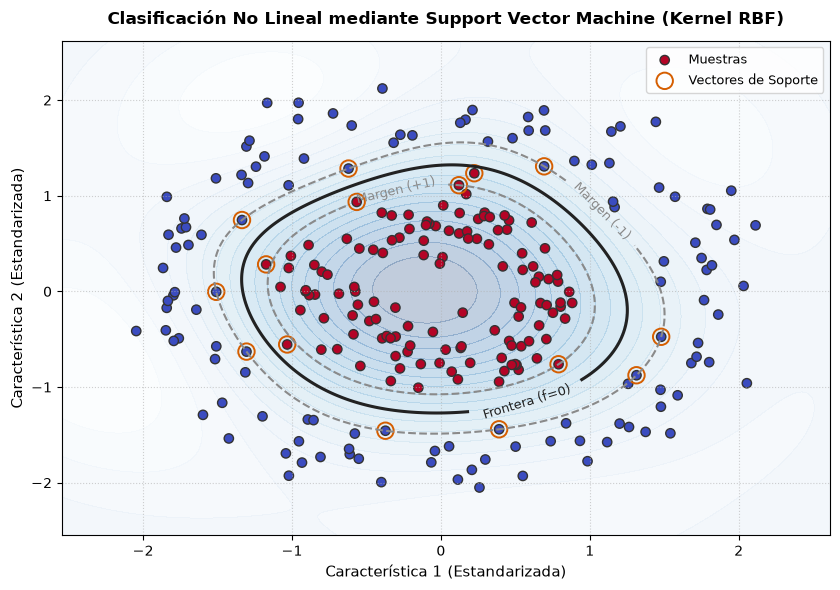

In [3]:
"""
Clasificación con Support Vector Machines (SVC).
Demuestra el efecto del kernel RBF y la identificación de vectores de soporte.
"""

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_circles
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import classification_report

# 1. Creación de un dataset no linealmente separable (anillos concéntricos)
X, y = make_circles(n_samples=250, factor=0.4, noise=0.1, random_state=42)

# 2. Preprocesamiento: Estandarización obligatoria para SVM
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Ajuste de SVM con Kernel RBF (Gaussian)
# C=10 (penalización balanceada) y gamma=0.5 (radio de curvatura del kernel)
svm_modelo = SVC(kernel='rbf', C=10.0, gamma=0.5, random_state=42)
svm_modelo.fit(X_scaled, y)

# 4. Extracción de Vectores de Soporte
vectores_soporte = svm_modelo.support_vectors_
n_vectores = len(vectores_soporte)

print("=" * 60)
print(f"Total de instancias de entrenamiento: {len(X)}")
print(f"Vectores de soporte identificados  : {n_vectores} ({n_vectores / len(X) * 100:.1f}%)")
print("=" * 60)
print(classification_report(y, svm_modelo.predict(X_scaled), target_names=['Clase 0', 'Clase 1']))

# 5. Generación de la Malla y Visualización de la Frontera
x_min, x_max = X_scaled[:, 0].min() - 0.5, X_scaled[:, 0].max() + 0.5
y_min, y_max = X_scaled[:, 1].min() - 0.5, X_scaled[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))

# Distancia firmada a la frontera (función de decisión: f(x) = 0)
Z = svm_modelo.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

fig, ax = plt.subplots(figsize=(8.5, 6), facecolor='white')
ax.set_facecolor('white')

# Superficie de decisión y bandas de margen (f(x) = -1, 0, +1)
ax.contourf(xx, yy, Z, levels=np.linspace(Z.min(), Z.max(), 20), cmap='Blues', alpha=0.25)
contornos = ax.contour(xx, yy, Z, levels=[-1, 0, 1], colors=['#8a8a8a', '#222222', '#8a8a8a'],
                       linestyles=['--', '-', '--'], linewidths=[1.5, 2.2, 1.5])
ax.clabel(contornos, inline=True, fontsize=9, fmt={-1: 'Margen (-1)', 0: 'Frontera (f=0)', 1: 'Margen (+1)'})

# Puntos de datos reales
scatter = ax.scatter(X_scaled[:, 0], X_scaled[:, 1], c=y, cmap='coolwarm', edgecolors='#333333', s=45, label='Muestras')

# Resaltar los vectores de soporte
ax.scatter(vectores_soporte[:, 0], vectores_soporte[:, 1], s=140, linewidth=1.4,
           facecolors='none', edgecolors='#d55e00', label='Vectores de Soporte')

ax.set_title("Clasificación No Lineal mediante Support Vector Machine (Kernel RBF)", fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel("Característica 1 (Estandarizada)", fontsize=10.5)
ax.set_ylabel("Característica 2 (Estandarizada)", fontsize=10.5)
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(frameon=True, facecolor='white', loc='upper right', fontsize=9.5)

plt.tight_layout()
plt.show()

## Problemas de clasificación

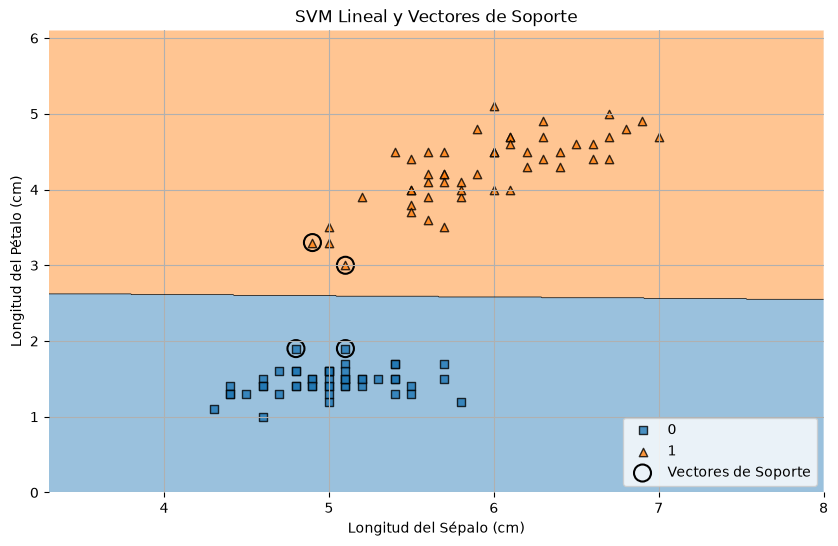


Resultados del Modelo:
Vector de Pesos (w): [0.02335031 1.42690438]
Sesgo (b): -3.8232002894833945
Ecuación del Hiperplano: 0.02*x1 + 1.43*x2 + -3.82 = 0


In [5]:
# 1. Importar Librerías
import numpy as np
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from mlxtend.plotting import plot_decision_regions # Para visualizar la frontera

# 2. Preparar los Datos (Usaremos un conjunto de datos simple)
# Cargamos el dataset Iris, solo con dos características (para poder graficarlo)
iris = datasets.load_iris()
X = iris.data[:, [0, 2]] # Tomamos la longitud del sépalo y la longitud del pétalo
y = iris.target

# Simplificamos a 2 clases para una clasificación binaria (Clase 0 vs Clase 1)
X = X[y != 2]
y = y[y != 2]

# 3. Entrenar el Modelo SVM
# Creamos el clasificador SVM:
# kernel='linear' indica que la frontera será una línea recta.
svm = SVC(kernel='linear', C=1.0, random_state=42)
svm.fit(X, y)

# 4. Visualizar la Frontera de Decisión y los Vectores de Soporte
# ---------------------------------------------------------------------
# NOTA: C es el parámetro de Regularización. Controla la penalización del error.
# Si C es pequeño, el margen es más grande (más errores permitidos).
# Si C es grande, el margen es más estrecho (menos errores permitidos).
# ---------------------------------------------------------------------

plt.figure(figsize=(10, 6))
# Trazamos la frontera de decisión:
plot_decision_regions(X, y, clf=svm, legend=2) 

# Marcamos los Vectores de Soporte (los puntos más importantes)
support_vectors = svm.support_vectors_
plt.scatter(support_vectors[:, 0], support_vectors[:, 1], s=150, 
            facecolors='none', edgecolors='k', linewidths=1.5, label='Vectores de Soporte')

plt.xlabel('Longitud del Sépalo (cm)')
plt.ylabel('Longitud del Pétalo (cm)')
plt.title('SVM Lineal y Vectores de Soporte')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

# 5. Imprimir la Ecuación (para relacionar con la teoría)
# Los coeficientes (w) y el intercepto (b)
w = svm.coef_[0]
b = svm.intercept_[0]
print(f"\nResultados del Modelo:")
print(f"Vector de Pesos (w): {w}")
print(f"Sesgo (b): {b}")
print(f"Ecuación del Hiperplano: {w[0]:.2f}*x1 + {w[1]:.2f}*x2 + {b:.2f} = 0")

## Ejemplo completo de clasificación con SVM (scikit-learn)

Mejor conjunto de hiperparámetros: {'svc__C': 1, 'svc__gamma': 'scale', 'svc__kernel': 'linear'}
Mejor score CV: 0.9644

Accuracy en test: 1.0000

Reporte de clasificación:
               precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        12
           1     1.0000    1.0000    1.0000        13
           2     1.0000    1.0000    1.0000        13

    accuracy                         1.0000        38
   macro avg     1.0000    1.0000    1.0000        38
weighted avg     1.0000    1.0000    1.0000        38



c:\Users\PATRICIO\Documents\github\ciencia-de-datos\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


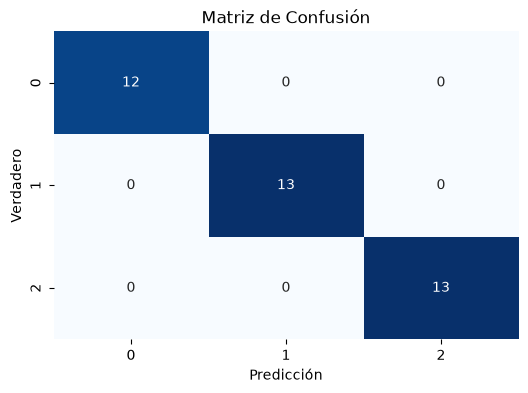

c:\Users\PATRICIO\Documents\github\ciencia-de-datos\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


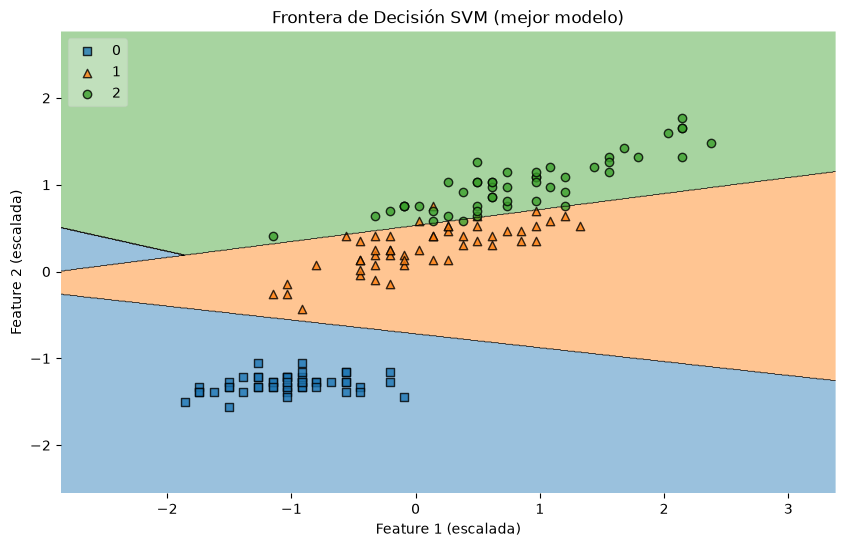

In [7]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import seaborn as sns
import numpy as np
from sklearn.svm import SVC as SVC_raw

# Ejemplo completo de clasificación con SVM (scikit-learn)
# Usa las variables/imports ya definidos en celdas previas (iris, datasets, plot_decision_regions, etc.)
# Nuevos imports necesarios:
import matplotlib.pyplot as plt

iris = datasets.load_iris()

# 1. Preparar datos (usamos Iris con 2 características para poder graficar fácilmente)
X = iris.data[:, [0, 2]]   # longitud sépalo, longitud pétalo
y = iris.target

# Dividir en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

# 2. Pipeline con escalado y SVC
pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('svc', SVC(probability=True, random_state=42))
])

# 3. Búsqueda de hiperparámetros con GridSearchCV
param_grid = {
    'svc__kernel': ['rbf', 'linear'],
    'svc__C': [0.1, 1, 10],
    'svc__gamma': ['scale', 0.01, 0.1]  # gamma solo relevante para rbf
}

grid = GridSearchCV(pipe, param_grid, cv=5, n_jobs=-1, verbose=0)
grid.fit(X_train, y_train)

print("Mejor conjunto de hiperparámetros:", grid.best_params_)
print(f"Mejor score CV: {grid.best_score_:.4f}")

# 4. Evaluación en test set
y_pred = grid.predict(X_test)
acc = accuracy_score(y_test, y_pred)
print(f"\nAccuracy en test: {acc:.4f}\n")
print("Reporte de clasificación:\n", classification_report(y_test, y_pred, digits=4))

# Matriz de confusión (visual)
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicción')
plt.ylabel('Verdadero')
plt.title('Matriz de Confusión')
plt.show()

# 5. Entrenar modelo final con los mejores hiperparámetros (para visualización)
best_params = grid.best_params_.copy()
# Extraer solo parámetros relevantes para SVC
svc_params = {k.split('__')[1]: v for k, v in best_params.items() if k.startswith('svc__')}
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

final_svc = SVC_raw(**svc_params, probability=True, random_state=42)
final_svc.fit(X_train_scaled, y_train)

# 6. Visualizar fronteras de decisión (usar datos escalados para el clasificador entrenado)
X_plot = np.vstack((X_train_scaled, X_test_scaled))
y_plot = np.hstack((y_train, y_test))

plt.figure(figsize=(10, 6))
# plot_decision_regions requiere las características en la misma escala que el clasificador espera.
plot_decision_regions(X_plot, y_plot, clf=final_svc, legend=2)
plt.title('Frontera de Decisión SVM (mejor modelo)')
plt.xlabel('Feature 1 (escalada)')
plt.ylabel('Feature 2 (escalada)')
plt.show()

In [7]:
# Titanic Dataset SVM Example
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

# 1) Cargar y preprocesar datos (edad y sexo)
titanic = pd.read_csv("../data/titanic.csv")
titanic = titanic[['Survived', 'Age', 'Sex']].dropna()
titanic['sex_num'] = titanic['Sex'].map({'male': 0, 'female': 1})
titanic.head()

,Survived,Age,Sex,sex_num
0,0,22.0,male,0
1,1,38.0,female,1
2,1,26.0,female,1
3,1,35.0,female,1
4,0,35.0,male,0


In [8]:
titanic.isnull().sum()

Survived    0
Age         0
Sex         0
sex_num     0
dtype: int64

#### Formulación del modelo

In [8]:
X_t = titanic[['Age', 'sex_num']].values
y_t = titanic['Survived'].values

# 2) Dividir en train/test
X_train_t, X_test_t, y_train_t, y_test_t = train_test_split(
    X_t, y_t, test_size=0.25, random_state=42, stratify=y_t
)

# 3) Escalado (StandardScaler) — usar nombres nuevos para no sobrescribir variables previas
scaler_t = StandardScaler()
X_train_t_scaled = scaler_t.fit_transform(X_train_t)
X_test_t_scaled = scaler_t.transform(X_test_t)

# 4) Entrenar SVM (clasificador) con parámetros razonables
svm_titanic = SVC(kernel='rbf', C=1.0, gamma='scale', probability=True, random_state=42)
svm_titanic.fit(X_train_t_scaled, y_train_t)

# 5) Evaluación
y_pred_t = svm_titanic.predict(X_test_t_scaled)
acc_t = accuracy_score(y_test_t, y_pred_t)
print(f"Accuracy (test): {acc_t:.4f}\n")
print("Reporte de clasificación:\n", classification_report(y_test_t, y_pred_t, digits=4))

# Matriz de confusión (visual)
cm_t = confusion_matrix(y_test_t, y_pred_t)
plt.figure(figsize=(5,4))
sns.heatmap(cm_t, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicción')
plt.ylabel('Verdadero')
plt.title('Matriz de Confusión - Titanic (edad + sexo)')
plt.show()

# 6) Visualizar frontera de decisión (usar datos escalados)
X_plot_t = np.vstack((X_train_t_scaled, X_test_t_scaled))
y_plot_t = np.hstack((y_train_t, y_test_t))

plt.figure(figsize=(10,6))
plot_decision_regions(X_plot_t, y_plot_t, clf=svm_titanic, legend=2)
# marcar vectores de soporte
sv = svm_titanic.support_vectors_
plt.scatter(sv[:,0], sv[:,1], s=120, facecolors='none', edgecolors='k', linewidths=1.5, label='Support vectors')
plt.xlabel('Edad (escalada)')
plt.ylabel('Sexo (escalado) [male=0, female=1]')
plt.title('Frontera de decisión SVM - Titanic (edad vs sexo)')
plt.legend(loc='upper right')
plt.show()


NameError: name 'titanic' is not defined

---
## Problemas de regresion
El algoritmo Support Vector Machine (SVM), aunque es popular para la clasificación, también se aplica a problemas de regresión. La implementación de SVM para regresión se conoce como Support Vector Regressor (SVR)

Mejores hiperparámetros (SVR): {'svr__C': 10, 'svr__epsilon': 0.1, 'svr__gamma': 'scale', 'svr__kernel': 'linear'}
Mejor score CV: 0.9293
MSE (test): 449.1246
R2  (test): 0.9219


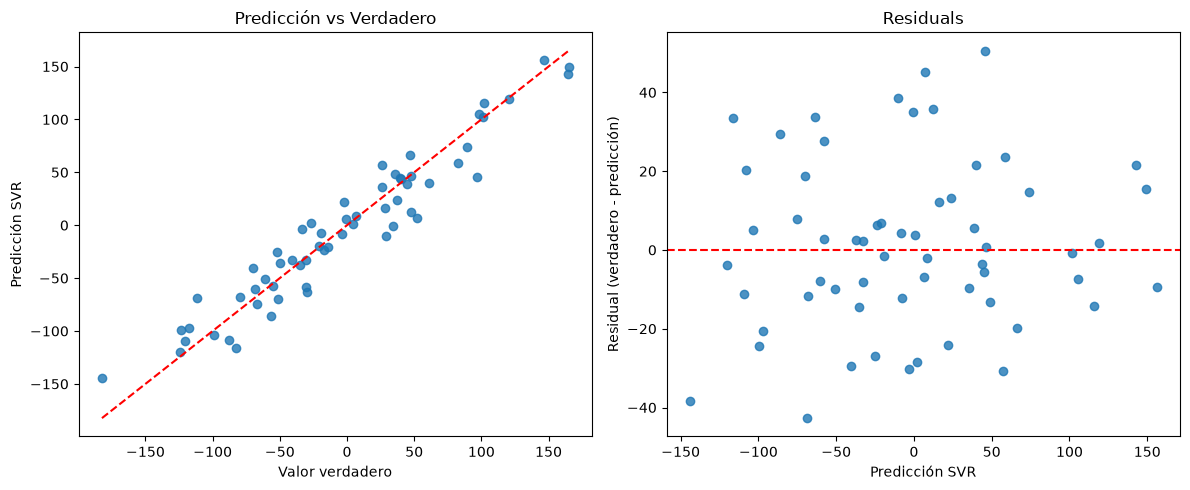

In [9]:
from sklearn.svm import SVR
from sklearn.datasets import make_regression
from sklearn.metrics import mean_squared_error, r2_score

# Ejemplo SVM para regresión con scikit-learn (SVR)
# Nuevo cell en el notebook (index 3)

# Imports necesarios (no sobrescriben variables existentes)

# 1) Crear un dataset sintético para regresión
X_reg, y_reg = make_regression(n_samples=300, n_features=2, noise=20.0, random_state=42)

# 2) Dividir en train/test (train_test_split ya está definido en el notebook)
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42
)

# 3) Pipeline: escalado + SVR
# Usamos Pipeline importado previamente
pipe_reg = Pipeline([
    ('scaler', StandardScaler()),
    ('svr', SVR())
])

# 4) Búsqueda de hiperparámetros (GridSearch)
param_grid_reg = {
    'svr__kernel': ['rbf', 'linear'],
    'svr__C': [0.1, 1, 10],
    'svr__epsilon': [0.1, 1.0],
    'svr__gamma': ['scale', 0.01, 0.1]  # relevante para rbf
}

grid_reg = GridSearchCV(pipe_reg, param_grid_reg, cv=5, n_jobs=-1, verbose=0)
grid_reg.fit(X_train_reg, y_train_reg)

print("Mejores hiperparámetros (SVR):", grid_reg.best_params_)
print(f"Mejor score CV: {grid_reg.best_score_:.4f}")

# 5) Evaluación en test
y_pred_reg = grid_reg.predict(X_test_reg)
mse = mean_squared_error(y_test_reg, y_pred_reg)
r2 = r2_score(y_test_reg, y_pred_reg)
print(f"MSE (test): {mse:.4f}")
print(f"R2  (test): {r2:.4f}")

# 6) Visualizaciones: predicción vs verdadero y residuales
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.scatter(y_test_reg, y_pred_reg, alpha=0.8)
plt.plot([y_test_reg.min(), y_test_reg.max()], [y_test_reg.min(), y_test_reg.max()], 'r--')
plt.xlabel('Valor verdadero')
plt.ylabel('Predicción SVR')
plt.title('Predicción vs Verdadero')

plt.subplot(1,2,2)
residuals = y_test_reg - y_pred_reg
plt.scatter(y_pred_reg, residuals, alpha=0.8)
plt.axhline(0, color='r', linestyle='--')
plt.xlabel('Predicción SVR')
plt.ylabel('Residual (verdadero - predicción)')
plt.title('Residuals')

plt.tight_layout()
plt.show()

### Ejemplo de Regresión con Support Vector Regressor (SVR)
**El Problema y los Datos: Estimación de Precios de Vivienda**

El objetivo es predecir los precios de las viviendas basándose en atributos de entrada.

Para este ejercicio se utiliza el conjunto de datos **Boston Housing**, disponible en la librería **scikit-learn**. Este conjunto de datos define cada punto de datos mediante 13 atributos (o características) y la tarea es estimar el precio de la vivienda (la variable objetivo continua)

c:\Users\PATRICIO\Documents\github\ciencia-de-datos\.venv\Lib\site-packages\sklearn\datasets\_openml.py:95: RuntimeWarning: Invalid cache, redownloading file to C:\Users\PATRICIO\scikit_learn_data\openml\openml.org\data/v1/download/52643/boston.arff.gz
  warn(


No se pudo cargar Boston desde OpenML; usando California Housing como fallback.
Fitting 5 folds for each of 54 candidates, totalling 270 fits
Dataset: California Housing (fallback)
Mejores hiperparámetros (SVR): {'svr__C': 10, 'svr__epsilon': 0.1, 'svr__gamma': 'auto', 'svr__kernel': 'rbf'}
Mejor score CV: 0.7602

MSE (test): 0.3237
R2  (test): 0.7530


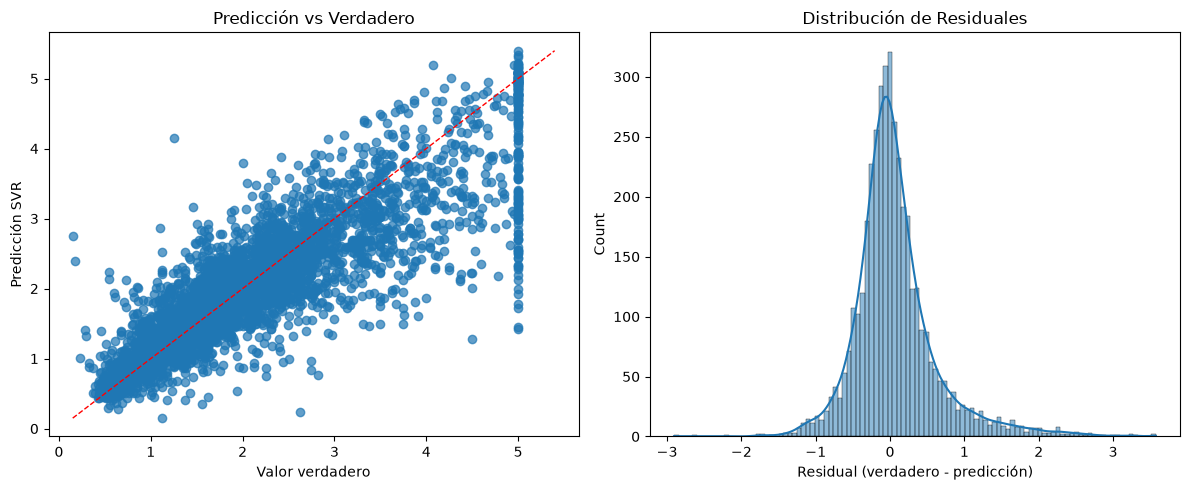

In [10]:
# SVM Regression sobre el dataset Boston (o fallback a California si Boston no está disponible)
# Usa imports ya presentes en el notebook: datasets, train_test_split, StandardScaler, Pipeline,
# GridSearchCV, SVR, mean_squared_error, r2_score, plt, sns, np

# 1) Cargar datos (intenta Boston; si falla, usa California Housing como fallback)
try:
    boston = datasets.fetch_openml(name='boston', version=1, as_frame=True)
    X = boston.data
    y = boston.target.astype(float)
    dataset_name = "Boston (OpenML)"
except Exception as e:
    cal = datasets.fetch_california_housing(as_frame=True)
    X = cal.data
    y = cal.target
    dataset_name = "California Housing (fallback)"
    print("No se pudo cargar Boston desde OpenML; usando California Housing como fallback.")

# 2) División train/test
X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 3) Pipeline: escalado + SVR
pipe_svr = Pipeline([
    ('scaler', StandardScaler()),
    ('svr', SVR())
])

# 4) GridSearchCV para hiperparámetros relevantes
param_grid_svr = {
    'svr__kernel': ['rbf', 'linear'],
    'svr__C': [0.1, 1, 10],
    'svr__epsilon': [0.1, 0.5, 1.0],
    'svr__gamma': ['scale', 'auto', 0.01]  # gamma aplica en rbf
}

grid_svr = GridSearchCV(pipe_svr, param_grid_svr, cv=5, n_jobs=-1, verbose=1)
grid_svr.fit(X_train_b, y_train_b)

print(f"Dataset: {dataset_name}")
print("Mejores hiperparámetros (SVR):", grid_svr.best_params_)
print(f"Mejor score CV: {grid_svr.best_score_:.4f}")

# 5) Evaluación en test set
y_pred_b = grid_svr.predict(X_test_b)
mse_b = mean_squared_error(y_test_b, y_pred_b)
r2_b = r2_score(y_test_b, y_pred_b)
print(f"\nMSE (test): {mse_b:.4f}")
print(f"R2  (test): {r2_b:.4f}")

# 6) Visualizaciones: Predicción vs Verdadero y residuales
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.scatter(y_test_b, y_pred_b, alpha=0.7)
min_v = min(y_test_b.min(), y_pred_b.min())
max_v = max(y_test_b.max(), y_pred_b.max())
plt.plot([min_v, max_v], [min_v, max_v], 'r--', lw=1)
plt.xlabel('Valor verdadero')
plt.ylabel('Predicción SVR')
plt.title('Predicción vs Verdadero')

plt.subplot(1,2,2)
res_b = y_test_b - y_pred_b
sns.histplot(res_b, kde=True)
plt.xlabel('Residual (verdadero - predicción)')
plt.title('Distribución de Residuales')

plt.tight_layout()
plt.show()

In [11]:
# EJEMPLO DE SUPPORT VECTOR REGRESSOR (SVR)
# VERSION SIMPLIFICADA

import numpy as np
from sklearn import datasets
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, explained_variance_score
from sklearn.utils import shuffle 
# Nota: En un entorno de producción, se recomienda usar también StandardScaler
# para escalar las características de entrada.

# --- 1. Cargar y Preparar Datos ---

# Cargar el conjunto de datos de viviendas (Boston Housing)
data = datasets.fetch_openml(name='boston', version=1, as_frame=True) # Conjunto de 506 muestras y 13 atributos

# Barajar (shuffle) los datos para evitar sesgos en el análisis 
X, y = shuffle(data.data, data.target, random_state=7)

# Dividir el conjunto de datos en entrenamiento (80%) y prueba (20%)
num_training = int(0.8 * len(X))

# Conjunto de Entrenamiento
X_train, y_train = X[:num_training], y[:num_training]
# Conjunto de Prueba
X_test, y_test = X[num_training:], y[num_training:]

# --- 2. Crear y Entrenar el Modelo SVR ---

# Crear el modelo SVR. Utilizamos un kernel lineal (lineal).
# C (Regularización): Parámetro de penalización por error de entrenamiento. 
# epsilon: Define un umbral de error; si la predicción está dentro de esta distancia, 
# no hay penalización.
sv_regressor = SVR(kernel='linear', C=1.0, epsilon=0.1)

# Entrenar el Support Vector Regressor
sv_regressor.fit(X_train, y_train)

# --- 3. Evaluar el Rendimiento ---

# Realizar predicciones sobre el conjunto de prueba (no visto)
y_test_pred = sv_regressor.predict(X_test)

# Calcular métricas de rendimiento (MSE y EVS)
mse = mean_squared_error(y_test, y_test_pred)
evs = explained_variance_score(y_test, y_test_pred)

# Imprimir el rendimiento 
print("\n#### Rendimiento del SVR ####")
print(f"Error Cuadrático Medio (MSE): {round(mse, 2)}")
print(f"Puntuación de Varianza Explicada (EVS): {round(evs, 2)}")

# --- 4. Predecir un Nuevo Punto de Dato ---

# Ejemplo de datos de entrada para una nueva vivienda (basado en 13 atributos)
test_data = [3.7, 0, 18.4, 1, 0.87, 5.95, 91, 2.5052, 26, 666, 20.2, 351.34, 15.27]

# Predicción del precio
predicted_price = sv_regressor.predict([test_data])
print(f"\nPrecio predicho para la vivienda de prueba: {predicted_price}")

c:\Users\PATRICIO\Documents\github\ciencia-de-datos\.venv\Lib\site-packages\sklearn\datasets\_openml.py:95: RuntimeWarning: Invalid cache, redownloading file to C:\Users\PATRICIO\scikit_learn_data\openml\openml.org\data/v1/download/52643/boston.arff.gz
  warn(


TypeError: expected string or bytes-like object, got 'int'

El Support Vector Regressor (SVR), al igual que el clasificador SVM, requiere la sintonización de parámetros para optimizar su rendimiento.

• **Kernel**: Especifica el tipo de hiperplano (o función) utilizado para modelar la relación. En este ejemplo, se utiliza el 'linear' kernel, asumiendo una relación lineal, aunque el algoritmo permite kernels no lineales como el RBF o polinomial.

• **C (Parámetro de Regularización)**: Este parámetro representa la penalización por el error de entrenamiento. Si aumenta el valor de C, el modelo se ajustará más para adaptarse a los datos de entrenamiento (buscando un margen de error más estricto), pero podría perder su capacidad de generalización (overfitting).

• **Epsilon (ϵ)**: Este parámetro es crucial para la regresión. Especifica un umbral. Si el valor predicho está dentro de esta distancia (ϵ) del valor real, no se aplica penalización por error de entrenamiento.

**Evaluación del Modelo**

Para evaluar el rendimiento de un modelo de regresión, se utilizan métricas que miden la diferencia entre los valores predichos y los valores reales.

• **Error Cuadrático Medio (Mean Squared Error, MSE)**: Mide la precisión promedio de las predicciones del regressor.

• **Puntuación de Varianza Explicada (Explained Variance Score, EVS)**: Mide qué proporción de la varianza total de la variable objetivo es capturada por el modelo. Un EVS de 1.0 representa una predicción perfecta.

El ejemplo muestra que la predicción de **18.52** para el punto de prueba es consistente con el objetivo real de los datos del conjunto de viviendas

## Optimización de **Hiperparámetros**

La optimización de los hiperparámetros **Kernel**, **C (regularización)** y **Gamma ($\gamma$)** en el algoritmo Support Vector Machine (SVM) utilizando `scikit-learn` se realiza de manera sistemática, generalmente a través de una combinación de **Búsqueda de Cuadrícula (Grid Search)** y **Validación Cruzada (Cross-Validation)**.

En la práctica, el ajuste de estos parámetros es un paso crítico y puede requerir experiencia especializada, especialmente si los datos presentan ruido o se superponen.

### Metodología de Optimización: Grid Search

El método más común y riguroso para la selección de hiperparámetros en `scikit-learn` es utilizar la clase `GridSearchCV`. Esta técnica implementa una **búsqueda exhaustiva** al evaluar todas las combinaciones posibles de los valores que el usuario define para cada parámetro de interés.

Para garantizar que el modelo seleccionado funcione bien con datos nuevos (es decir, que **generalice** adecuadamente y no sufra de sobreajuste), la búsqueda de cuadrícula se ejecuta dentro de un esquema de **Validación Cruzada**.

El proceso general de optimización implica:

1.  **Definición de la Cuadrícula:** Crear un diccionario (`param_grid`) que contenga los nombres de los parámetros y una lista de valores a probar para cada uno.

2.  **Entrenamiento y Evaluación:** `GridSearchCV` entrena el modelo para cada combinación de parámetros y evalúa su rendimiento utilizando la precisión promedio obtenida de la validación cruzada (por ejemplo, 5-fold cross-validation).

3.  **Selección del Mejor Modelo:** Finalmente, se elige la combinación de hiperparámetros que produce la **mejor puntuación media de validación cruzada** (`best_score_`).

### 1. Optimización del Kernel

El parámetro `Kernel` es fundamental ya que selecciona el tipo de hiperplano utilizado para separar los datos.

*   **Valores a Probar:** Se deben incluir los diferentes tipos de kernels, como el kernel lineal (`'linear'`), el kernel de función de base radial (`'rbf'`), o el kernel polinomial (`'poly'`), dependiendo de si se requiere una frontera de decisión lineal o no lineal.

*   **Combinación Condicional:** Dado que los kernels no lineales (como `'rbf'`) requieren el parámetro $\gamma$, y el kernel `'linear'` no lo requiere, la cuadrícula de parámetros a menudo se define como una **lista de diccionarios**, donde cada diccionario prueba un tipo de kernel y sus parámetros específicos (si aplica).

### 2. Optimización del Parámetro C (Regularización)

El parámetro $C$ es la **constante de regularización**, que penaliza el término de error en la función de coste y controla el compromiso entre tener un margen de decisión amplio y la correcta clasificación de los puntos de entrenamiento.

*   **Rango de Búsqueda:** $C$ se utiliza para controlar la complejidad del modelo (donde un $C$ alto puede llevar a un sobreajuste). Por lo tanto, se recomienda buscar su valor en una **escala logarítmica** (por ejemplo, valores como 0.001, 0.01, 0.1, 1, 10, 100) para explorar adecuadamente cómo la magnitud de la restricción afecta el modelo.

### 3. Optimización del Parámetro Gamma ($\gamma$)

El parámetro $\gamma$ es específico de los kernels no lineales, y determina la influencia que tienen los puntos de entrenamiento en la definición del hiperplano.

*   **Rango de Búsqueda:** Un valor de $\gamma$ alto hace que solo los puntos cercanos influyan, lo que **aumenta el riesgo de sobreajuste**. Al igual que $C$, el parámetro $\gamma$ debe ser sintonizado en una **escala logarítmica** como parte del diccionario de parámetros para los kernels no lineales.

En resumen, el SVM es sensible a la selección de parámetros, y la sintonización adecuada, que combina la exploración sistemática (Grid Search) con la evaluación rigurosa (Cross-Validation), es esencial para obtener el mejor rendimiento de generalización.

### Nota sobre Preprocesamiento

Es fundamental tener en cuenta que el rendimiento de SVM es muy sensible a la **escala de los datos**. Por esta razón, antes de ejecutar la búsqueda de parámetros, es una práctica común **normalizar o estandarizar** los datos de entrada para que todas las características varíen en un rango similar, lo cual se realiza utilizando métodos como `MinMaxScaler` o `StandardScaler`.

### Explicación del Proceso

El objeto GridSearchCV automatiza el proceso de tunning de hiperparámetros. Durante el proceso de fit:
1. **Iteración y Validación Cruzada**: GridSearchCV entrena el modelo para cada una de las combinaciones de parámetros definidas en param_grid, utilizando validación cruzada (en este caso, 5-Fold, donde los datos de entrenamiento se dividen en 5 subconjuntos para garantizar la fiabilidad de la evaluación).

2. **Ajuste del Modelo**: En cada iteración de la validación cruzada, el pipeline interno garantiza que el escalado de datos (StandardScaler) se aplique solo a los datos de entrenamiento de ese fold específico, previniendo la fuga de información (information leakage).

3. **Selección**: Una vez que se prueban todas las combinaciones, GridSearchCV selecciona automáticamente la combinación de hiperparámetros (best_params_) que resultó en el mejor rendimiento promedio durante la fase de validación cruzada (best_score_).

4. **Modelo Final**: Finalmente, GridSearchCV ajusta un modelo definitivo utilizando los mejores parámetros encontrados y el conjunto completo de datos de entrenamiento inicial (X_train). Este modelo se almacena en el atributo best_estimator_ y es el que se utiliza para hacer predicciones en el conjunto de prueba (X_test)

In [13]:
# kernels
"""
Comparativa Práctica de Kernels en Scikit-Learn.
Demuestra la sintaxis y evaluación de rendimiento entre kernels sobre un dataset no lineal.
"""

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# 1. Carga de datos reales y estandarización obligatoria
datos = load_breast_cancer()
X, y = datos.data, datos.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 2. Configuración y evaluación de los distintos kernels
kernels = {
    'Lineal': SVC(kernel='linear', C=1.0, random_state=42),
    'RBF Gaussiano': SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42),
    'Polinomial (Grado 3)': SVC(kernel='poly', degree=3, C=1.0, random_state=42),
    'Sigmoide': SVC(kernel='sigmoid', C=1.0, gamma='scale', random_state=42)
}

print("=" * 60)
print("EVALUACIÓN DE KERNELS DE SVM (BREAST CANCER TEST SET)")
print("=" * 60)

for nombre, modelo in kernels.items():
    modelo.fit(X_train_scaled, y_train)
    exactitud = modelo.score(X_test_scaled, y_test)
    n_vectores = len(modelo.support_vectors_)
    print(f"Kernel: {nombre:<22} | Exactitud: {exactitud*100:.2f}% | Vectores Soporte: {n_vectores}")

EVALUACIÓN DE KERNELS DE SVM (BREAST CANCER TEST SET)
Kernel: Lineal                 | Exactitud: 98.25% | Vectores Soporte: 31
Kernel: RBF Gaussiano          | Exactitud: 97.66% | Vectores Soporte: 91
Kernel: Polinomial (Grado 3)   | Exactitud: 89.47% | Vectores Soporte: 125
Kernel: Sigmoide               | Exactitud: 93.57% | Vectores Soporte: 57


In [12]:
# TITANIC DATASET SVM EXAMPLE
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC

df = pd.read_csv('../data/titanic.csv')
df['sex_num'] = df['Sex'].map({'male': 0, 'female': 1})
# Usar transform para propagar la media de cada grupo a las filas correspondientes
df['Age'] = df.groupby('Pclass')['Age'].transform(lambda grp: grp.fillna(grp.mean())).round().astype(int)

# Formulacion de modelo
X = df[['Age', 'sex_num']].values
y = df['Survived'].values

# validacion cruzada
X_train, X_test, y_train, y_test = train_test_split(X, y, 
                                                    test_size=0.20, 
                                                    random_state=46)

# Modelamiento SVM
svm_titanic = SVC(kernel='linear', C=1.0, gamma='scale', probability=True, random_state=42)
svm_titanic.fit(X_train, y_train)

# Optimizacion de hiperparametros con GridSearchCV
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score

# Crear un Pipeline para estandarizar los datos antes de aplicar SVM
# Esto asegura que todas las características tengan media 0 y varianza 1, lo cual es vital para los SVM con kernel no lineales.
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(random_state=42, probability=True)) 
])

# Definición de la cuadrícula de búsqueda (Grid)
# Usamos notación de doble guion bajo '__' para referenciar parámetros dentro del Pipeline
param_grid = [
    {
        'svm__kernel': ['rbf'],
        'svm__C': [0.1, 1, 10, 100],  # Probando valores de C en escala logarítmica
        'svm__gamma': [0.001, 0.01, 0.1, 1] # Probando valores de gamma
    },
    {
        'svm__kernel': ['linear'],
        'svm__C': [0.1, 1, 10, 100]
    }
]
# El GridSearchCV probará todas las combinaciones posibles: 4x4=16 para rbf, 
# y 4 para linear (total 20 combinaciones).

# Configurar y ejecutar GridSearchCV
# Usamos cv=5, indicando 5-fold cross-validation.
grid_search = GridSearchCV(pipeline, param_grid, cv=5, scoring='accuracy', n_jobs=-1)

# El proceso de fitting entrenará 20 combinaciones x 5 folds = 100 modelos.
grid_search.fit(X_train, y_train)

# Extracción de Resultados

print("Mejores parámetros encontrados (en el set de entrenamiento):")
print(grid_search.best_params_)

print("\nMejor puntuación media de validación cruzada (best_score_):")
print(f"{grid_search.best_score_:.4f}")

# Evaluación final en el set de prueba (test set)
y_pred = grid_search.predict(X_test)
final_accuracy = accuracy_score(y_test, y_pred)

print("\nPrecisión en el conjunto de prueba (Test Set Accuracy):")
print(f"{final_accuracy:.4f}")

FileNotFoundError: [Errno 2] No such file or directory: '../data/titanic.csv'

In [14]:
# prediccion
# Nuevo dato: edad=25, sexo=0
nuevo = np.array([[28, 1]])

mejor = grid_search.best_estimator_
pred = mejor.predict(nuevo)

label_map = {0: "No sobrevivió", 1: "Sobrevivió"}
print(f"Predicción (clase): {pred[0]} -> {label_map[int(pred[0])]}")

# Intentar mostrar probabilidades si el estimador las soporta
try:
    probs = mejor.predict_proba(nuevo)[0]
    print(f"Probabilidades (no, sí): {probs}")
except Exception:
    print("El estimador no soporta predict_proba. " \
    "Reentrene el pipeline con SVC(probability=True) para obtener probabilidades.")

Predicción (clase): 1 -> Sobrevivió
Probabilidades (no, sí): [0.25941319 0.74058681]
